#### Oversampling
Using SMOTE


Creates synthetic samples specifically for the minority class, based on nearest neighbors. (Yes, KNN!) It's quite a useful way to synthesize data when you want to ensure the rarer combinations need representation.

In [1]:
# pip install imblearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Loading the dataset
# This time the target is TouchScreen (0/1), so the goal is to oversample
# the rare class (laptops with a touch screen).
df = pd.read_csv("../../laptopprice_dataset_cleaned.csv")


df

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,0,1,0,0,0,1,0,1,0,0
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,0,1,0,0,0,1,0,1,0,0
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,0,1,0,0,0,1,0,0,1,0
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,0,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,4,2.20,10.555257,0,0,100.454670,500,0,0,0,...,0,0,1,0,0,0,1,0,0,1
1269,4,1.80,10.433899,1,1,157.350512,0,128,0,0,...,0,0,1,0,0,1,0,0,0,1
1270,16,1.30,11.288115,1,1,276.053530,0,512,0,0,...,0,0,1,0,0,1,0,0,0,1
1271,2,1.50,9.409283,0,0,111.935204,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1


In [2]:
# remove NaNs
df = df.dropna()

#### The problem

<Axes: xlabel='TouchScreen', ylabel='Count'>

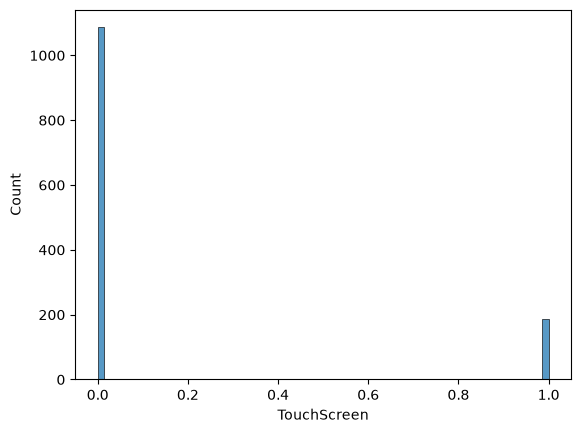

In [3]:

sns.histplot(df, x="TouchScreen")

# Laptops with a touch screen are underrepresented (187 vs 1086 without).
# Assume we cannot collect more data, so we create synthetic samples
# to represent the rare class better.

In [4]:
# 1086 without touch screen (85%) vs 187 with touch screen (15%)
df['TouchScreen'].value_counts()

TouchScreen
0    1086
1     187
Name: count, dtype: int64

#### SMOTE

In [5]:
# Original shape: 1273 rows, 44 columns
df.shape

(1273, 44)

In [6]:
# Split features (X) and target (y), so the target is not part of the features
# when SMOTE creates the new rows (prevents data leakage).
X = df.drop(columns="TouchScreen", axis=1)
y = df['TouchScreen']

<Axes: xlabel='TouchScreen', ylabel='Count'>

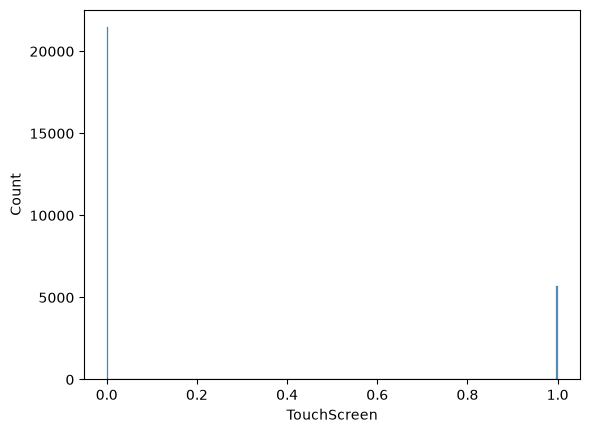

In [7]:
from imblearn.over_sampling import SMOTE
# SMOTE can only ADD rows, so each value must be >= the original count of that class
strategy = {
    0: 21450,
    1: 5713
}

# SMOTE creates new rows by interpolating between a real row and one of its
smote = SMOTE(sampling_strategy=strategy)

X_resampled, y_resampled = smote.fit_resample(X, y)

# Rebuild the dataframe (TouchScreen is added back as the last column)
df_oversampled_smote = pd.DataFrame(X_resampled)
df_oversampled_smote["TouchScreen"] = y_resampled

sns.histplot(df_oversampled_smote, x="TouchScreen")

In [8]:
# 1273 -> 27163 rows (about 21 times larger)

df_oversampled_smote.shape

(27163, 44)

In [9]:
# 0: 21450, 1: 5713. Touch screen laptops are now 21% of the data (before 15%).
df_oversampled_smote['TouchScreen'].value_counts()

TouchScreen
0    21450
1     5713
Name: count, dtype: int64

In [10]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [ ]:
# Original: 1273 rows. Ips mean = 0.28, Ram mean = 8.45
df.describe()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
count,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,...,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00
mean,8.45,2.04,10.83,0.15,0.28,146.95,413.72,186.25,0.08,0.02,...,0.11,0.33,0.40,0.11,0.14,0.55,0.31,0.02,0.12,0.86
std,5.10,0.67,0.62,0.35,0.45,42.93,518.05,186.53,0.27,0.13,...,0.31,0.47,0.49,0.31,0.34,0.50,0.46,0.13,0.32,0.34
min,2.00,0.69,9.13,0.00,0.00,90.58,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.50,10.39,0.00,0.00,127.34,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
50%,8.00,2.04,10.87,0.00,0.00,141.21,0.00,256.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00
75%,8.00,2.31,11.29,0.00,1.00,157.35,1000.00,256.00,0.00,0.00,...,0.00,1.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00
max,64.00,4.70,12.69,1.00,1.00,352.47,2000.00,1024.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [ ]:
# After SMOTE: 27163 rows. Numeric columns stay close (Price mean 10.83 -> 10.84,
# Weight 2.04 -> 2.00, SSD 186.25 -> 192.81), but some binary columns shift
# (Ips mean 0.28 -> 0.17).
df_oversampled_smote.describe()

,Ram,Weight,Price,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,Company_Asus,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,TouchScreen
count,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,...,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00
mean,8.39,2.01,10.85,0.17,149.70,395.28,192.78,0.03,0.01,0.05,...,0.24,0.34,0.08,0.07,0.53,0.23,0.01,0.06,0.83,0.21
std,4.73,0.63,0.60,0.38,44.74,513.83,190.12,0.17,0.11,0.21,...,0.43,0.47,0.27,0.26,0.50,0.42,0.11,0.24,0.38,0.41
min,2.00,0.69,9.13,0.00,90.58,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.49,10.42,0.00,127.34,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
50%,8.00,2.03,10.89,0.00,141.21,0.00,256.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00
75%,8.00,2.28,11.31,0.00,157.60,1000.00,256.00,0.00,0.00,0.00,...,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00
max,64.00,4.70,12.69,1.00,352.47,2000.00,1024.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [ ]:
# Variance of the original data
df.var(numeric_only=True)

Ram                                   26.00
Weight                                 0.45
Price                                  0.38
TouchScreen                            0.13
Ips                                    0.20
Ppi                                 1842.71
HDD                               268380.45
SSD                                34794.03
Company_Acer                           0.07
Company_Apple                          0.02
Company_Asus                           0.10
Company_Chuwi                          0.00
Company_Dell                           0.18
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.17
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.18
Company_MSI                            0.04
Company_Mediacom                       0.01
Company_Microsoft                      0.00
Company_Razer                   

In [ ]:
# Most numeric variances stay in the same range (Price 0.38 -> 0.36, HDD 268380 -> 262724),
# but several columns changed clearly: Ram 26.00 -> 21.76, Ppi 1842.71 -> 2000.95,
# Company_Acer 0.07 -> 0.03, Company_Asus 0.10 -> 0.04, Ips 0.20 -> 0.14.
# TouchScreen variance rose 0.13 -> 0.17 because the classes are now more balanced.
df_oversampled_smote.var(numeric_only=True)

Ram                                   22.39
Weight                                 0.40
Price                                  0.36
Ips                                    0.14
Ppi                                 2001.24
HDD                               264022.82
SSD                                36146.90
Company_Acer                           0.03
Company_Apple                          0.01
Company_Asus                           0.04
Company_Chuwi                          0.00
Company_Dell                           0.13
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.10
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.11
Company_MSI                            0.03
Company_Mediacom                       0.00
Company_Microsoft                      0.00
Company_Razer                          0.00
Company_Samsung                 

<Axes: >

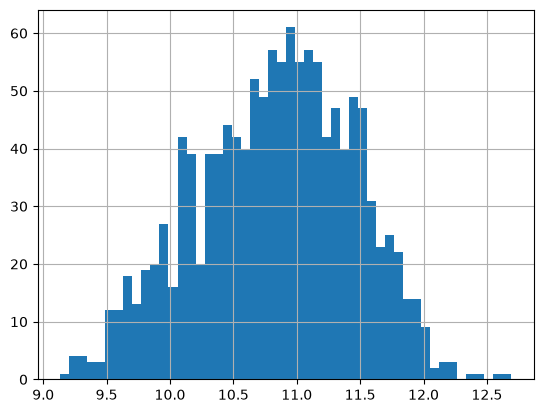

In [ ]:
# Price distribution before SMOTE
df['Price'].hist(bins=50)

<Axes: >

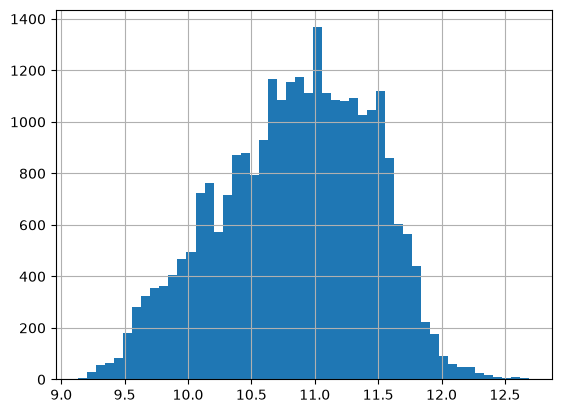

In [ ]:
# Price distribution after SMOTE 
df_oversampled_smote['Price'].hist(bins=50)

In [ ]:
# to be added later => extract only the synthetic ones from the oversampled df
# so we can actually study the synthesized houses here

# got this from AI / ChatGPT
diff = (
    df_oversampled_smote.merge(df.drop_duplicates(), how="left", indicator=True)
       .query('_merge == "left_only"')
       .drop(columns="_merge")
)

# Extract only the synthetic rows: a left merge with the original data,
# then keep the rows that exist only in the oversampled data ("left_only").

# These are the synthetic laptops only. Some values are unrealistic, e.g.
# Ram of 7, 11 or 30 GB (real laptops use 4, 8, 16, 32) and SSD of 21 GB.
# SMOTE interpolates numbers, so it does not know which values are realistic.
diff

,Ram,Weight,Price,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,Company_Asus,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,TouchScreen
1273,8,2.75,10.86,1,141.21,1000,0,0,0,0,...,0,1,0,0,0,1,0,0,1,0
1274,4,2.14,9.75,0,100.45,500,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1275,8,1.47,11.17,0,157.35,0,256,0,0,0,...,0,1,0,0,1,0,0,0,1,0
1276,8,2.06,10.39,0,100.45,2000,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1277,8,2.58,11.04,0,127.34,1000,0,0,0,0,...,0,1,0,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27158,16,1.30,11.76,0,218.76,0,512,0,0,0,...,0,1,0,0,1,0,0,0,0,1
27159,8,1.60,10.97,1,165.63,0,256,0,0,0,...,1,0,0,0,1,0,0,0,1,1
27160,21,2.13,12.18,0,225.13,0,1000,0,0,0,...,0,1,0,0,0,0,0,0,1,1
27161,16,1.28,11.83,0,203.02,0,512,0,0,0,...,0,1,0,0,1,0,0,0,1,1


SMOTE increased the touch screen class from 187 to 5713 rows and kept the numeric statistics close to the original (for example Price mean 10.83 → 10.84). However, the dataset grew to 27163 rows, around 95% of them synthetic, some binary columns changed noticeably (for example Ips mean 0.28 → 0.17), and the synthetic rows contain unrealistic values (Ram of 7 or 30 GB, SSD of 21 GB). A smaller target size and SMOTENC for the categorical columns would give more realistic results